# Лабораторная работа № 6 — блокнот качества данных

**Студент:** Подольский Ф. А., ПМИ-3-2025 · **Вариант 5:** репозитории и активность (GitHub API + HTML-страницы github.com)

Блокнот — протокол работы конвейера на собранных данных: сырой слой и происхождение записей, сравнение форматов, шесть шагов очистки, контракт, пересборка без сети, БД (три прогона, история, ограничения), метрики со «светофором», слой mart с графиками.

**Порядок запуска:** сначала `./run_real.sh` (или `python -m src.collect`, `python -m src.corrupt`, `python -m src.pipeline`), затем *Run All*. Все ячейки только читают артефакты или повторяют безопасные для данных шаги: пересборка clean детерминирована, демонстрационная база пересоздаётся.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # блокнот открыт не из корня лабораторной
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display

from src import clean, config, contract, duckdb_bench, fill_report, formats, mart, quality, rawio, rebuild
from db import load as dbload

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

print("Данные:", config.DATA_ROOT)
print("pandas", pd.__version__)
SIM = fill_report.is_simulation()
if SIM:
    display(Markdown("> ⚠ **Данные получены на локальной имитации (синтетические фикстуры)** — цифры ниже не реальные."))

Данные: /sessions/rcw-012ewfrivctrzzfvfwmihxbt/run/lab6
pandas 2.3.3


## 1. Сырой слой: JSON Lines + происхождение

Файлы только дописываются. После каждой дозаписи в `raw/MANIFEST.jsonl` фиксируются размер и SHA-256, и `rawio.verify()` проверяет, что уже записанные байты не изменились.

In [2]:
rows = []
for p in sorted(config.RAW_DIR.glob("*.jsonl")):
    if p.name == config.RAW_MANIFEST.name:
        continue
    recs = rawio.read_jsonl(p)
    chk = rawio.verify(p)
    rows.append({"файл": p.name, "строк": len(recs), "КБ": round(p.stat().st_size / 1024, 1),
                 "сущности": pd.Series([r.get("_entity") for r in recs]).value_counts().to_dict(),
                 "дозаписей": chk.get("appends"), "неизменность": chk.get("checked")})
display(pd.DataFrame(rows))

,файл,строк,КБ,сущности,дозаписей,неизменность
0,github_api.jsonl,3612,3704.1,"{'issue': 3600, 'repo': 12}",12,True
1,github_html.jsonl,264,192.3,"{'release': 240, 'repo_page': 24}",13,True
2,synthetic_dirty.jsonl,272,290.3,"{'issue': 252, 'release': 17, 'repo_page': 2, 'repo': 1}",2,True


In [3]:
# По одной записи каждой сущности: служебные поля происхождения и сырые значения «как со страницы»
api = rawio.read_jsonl(config.RAW_API)
html = rawio.read_jsonl(config.RAW_HTML)
meta_cols = ["_entity", "_source", "_source_url", "_collected_at", "_parser_version", "_status", "_run_id"]
sample = {e: next(r for r in api + html if r.get("_entity") == e) for e in ("repo", "issue", "repo_page", "release")}
display(pd.DataFrame({e: {k: r.get(k) for k in meta_cols} for e, r in sample.items()}))
page = sample["repo_page"]
display(pd.Series({k: v for k, v in page.items() if k.endswith("_raw")}, name="repo_page: сырые значения").to_frame())

,repo,issue,repo_page,release
_entity,repo,issue,repo_page,release
_source,github_api,github_api,github_html,github_html
_source_url,https://api.github.com/repos/scrapy/scrapy,https://api.github.com/repos/scrapy/scrapy/issues?state=all&per_page=100&sort=updated&...,https://github.com/scrapy/scrapy,https://github.com/scrapy/scrapy/releases
_collected_at,2026-10-15T21:07:40.294+00:00,2026-10-15T21:07:42.472+00:00,2026-10-15T21:09:27.012+00:00,2026-10-15T21:09:30.707+00:00
_parser_version,github-api/1.0,github-api/1.0,github-html/1.0,github-html/1.0
_status,200,200,200,200
_run_id,20261015T210737Z,20261015T210737Z,20261015T210922Z,20261015T210922Z


,repo_page: сырые значения
repo_nwo_raw,scrapy/scrapy
repository_id_raw,529502
about_raw,"Scrapy, a fast high-level web crawling & scraping framework for Python."
homepage_raw,None
topics_raw,[]
license_raw,BSD-3-Clause license
stars_raw,None
stars_title_raw,None
forks_raw,12.0k
forks_title_raw,None


In [4]:
# Синтетическая порча — отдельный файл, каждая запись помечена
syn = rawio.read_jsonl(config.RAW_SYNTHETIC)
real_n = len(api) + len(html)
print(f"Синтетических записей: {len(syn)} ({len(syn) / max(1, real_n):.1%} от реальных)")
display(pd.Series([r["_corruption"] for r in syn]).value_counts().rename("записей").to_frame())

Синтетических записей: 272 (7.0% от реальных)


,записей
full_duplicate,55
tracking_url,35
nbsp_zero_width,35
closed_without_closed_at,22
created_in_future,18
negative_comments,17
orphan_repo,16
bad_date,14
closed_before_created,13
merged_issue,13


## 2. Форматы хранения: CSV, JSON Lines, Parquet

Замер на своём наборе (`clean/dataset.parquet`), время — медиана из 7 повторов. Особое внимание — к дате UTC и строкам с ведущим нулём (`label_color = "008672"`, короткий SHA).

In [5]:
bench, meta = formats.run()
display(bench.set_index("формат").T)
print(f"Parquet меньше CSV в {meta['csv_to_parquet_size_ratio']} раза")
print("Ловушка CSV на партии из одних цифр:", meta["csv_digits_only_batch"])

формат,CSV,JSON Lines,JSON Lines + gzip,Parquet (zstd)
строк,3720,3720,3720,3720
"размер, КБ",1824.1,3160.1,279.8,283.8
"чтение всего, мс",11.8,32.6,37.7,3.6
"чтение 3 столбцов, мс",5.8,32.8,38.3,1.1
тип created_at,object,"datetime64[ns, UTC]","datetime64[ns, UTC]","datetime64[ns, UTC]"
тип label_color,object,object,object,object
label_color «033166» →,'033166','033166','033166','033166'
commit_sha «0c5e5e1» →,'0c5e5e1','0c5e5e1','0c5e5e1','0c5e5e1'
тип comments (Int64 с пропусками),float64,float64,float64,Int64
тип labels (список),str,list,list,ndarray


Parquet меньше CSV в 6.4 раза
Ловушка CSV на партии из одних цифр: {'строк в партии': 36, 'было': '033166', 'стало после CSV': '33166', 'тип': 'int64', 'с dtype=str': "'033166'"}


## 3. Очистка: шесть шагов с протоколом

Шаги фиксированы: нормализация текста → бизнес-ключ → типизация → пропуски → дубликаты → бизнес-правила; затем контракт pydantic. `clean.build()` не использует ни сеть, ни текущее время.

In [6]:
res = clean.build()
protocol = res.protocol.frame()
display(protocol)

,шаг,сущность,строк до,строк после,изменено,удалено,в rejects,примечание
0,0. чтение raw,repos_api,13,13,0,0,0,из них синтетических: 1
1,0. чтение raw,repos_html,26,26,0,0,0,из них синтетических: 2
2,0. чтение raw,events,4109,4109,0,0,0,из них синтетических: 269
3,1. нормализация текста,repos_api,13,13,1,0,0,исправлено значений — homepage: 1
4,1. нормализация текста,repos_html,26,26,0,0,0,исправлено значений — нет
5,1. нормализация текста,events,4109,4109,116,0,0,исправлено значений — title: 116
6,2. бизнес-ключ,repos_api,13,13,0,0,0,"repo_key построен: 13, не построен: 0"
7,2. бизнес-ключ,repos_html,26,26,2,0,0,repo_key построен: 26; URL очищено от трекинга: 2
8,2. бизнес-ключ,events,4109,4109,33,0,0,"event_key построен: 4109, не построен: 0; URL с трекингом нормализовано: 33"
9,3. типизация,repos_api,13,13,0,0,0,целые: 6 полей → Int64; даты → UTC; ошибок приведения: 0


In [7]:
# Как работают шаги 1–2 на «почти-дублях»: сырой заголовок и URL против очищенных
nbsp = [r for r in syn if r["_corruption"] in ("nbsp_zero_width", "tracking_url")][:3]
display(pd.DataFrame([{"порча": r["_corruption"], "сырой title (repr)": repr(r.get("title") or r.get("title_raw")),
                       "сырой URL": r.get("html_url") or r.get("_source_url"),
                       "после нормализации": clean.normalize_text(r.get("title") or r.get("title_raw")),
                       "канонический URL": clean.canonical_url(r.get("html_url") or r.get("_source_url"))}
                      for r in nbsp]))

,порча,сырой title (repr),сырой URL,после нормализации,канонический URL
0,tracking_url,'Filter SelectorList with custom predicate?',https://github.com/scrapy/parsel/issues/142?utm_source=newsletter&utm_medium=email,Filter SelectorList with custom predicate?,https://github.com/scrapy/parsel/issues/142
1,tracking_url,'Fix JSON Schema cache key mismatch with nested `json_schema_mode_override`',https://github.com/pydantic/pydantic/pull/13980?utm_source=newsletter&utm_medium=email,Fix JSON Schema cache key mismatch with nested `json_schema_mode_override`,https://github.com/pydantic/pydantic/pull/13980
2,nbsp_zero_width,' Rebind the lambda of\xa0\u200b\xa0the list_reduce aliases like list_reduce \n',https://github.com/duckdb/duckdb/pull/27124,Rebind the lambda of the list_reduce aliases like list_reduce,https://github.com/duckdb/duckdb/pull/27124


In [8]:
display(pd.DataFrame(res.rules))
print("Типы чистого слоя (события):")
print(res.events.dtypes.to_string())

,сущность,правило,нарушений,"доля, %"
0,repository,R-01 репозиторий подтверждён API (есть карточка /repos),0,0.00
1,repository,"R-02 счётчики API ≥ 0 (stars, forks, watchers, open issues)",0,0.00
2,repository,R-03 created_at ≤ pushed_at и ≤ момента сбора,0,0.00
3,repository,R-04 id репозитория на странице = id в API,0,0.00
4,repository,R-05 звёзды на странице ≈ звёзды в API (±2 % или погрешность «k»),0,0.00
5,repository,"R-06 счётчики HTML ≥ 0, доля языка 0–100 %",0,0.00
6,event,E-01 событие не из будущего (created_at ≤ момента сбора),18,0.47
7,event,E-02 closed_at ≥ created_at,27,0.70
8,event,E-03 state=closed ⇔ задан closed_at (issue/PR),22,0.57
9,event,"E-04 merged_at только у PR, не раньше создания и только у закрытого",20,0.52


Типы чистого слоя (события):
event_key                          object
repo_key                           object
event_type                         object
github_id                           Int64
number                              Int64
tag                                object
title                              object
state                              object
state_reason                       object
is_draft                          boolean
author_association                 object
author_is_bot                     boolean
labels                             object
label_color                        object
comments                            Int64
reactions                           Int64
created_at            datetime64[ns, UTC]
gh_updated_at         datetime64[ns, UTC]
closed_at             datetime64[ns, UTC]
merged_at             datetime64[ns, UTC]
commit_sha                         object
url                                object
source                             object
sourc

## 4. Контракт данных (pydantic) на заведомо битых записях

In [9]:
from src.pipeline import contract_probes
probes = contract_probes()
display(probes)
assert (probes["результат"] == "отклонена").all(), "контракт пропустил битую запись"

,модель,проверка,результат,поле,сообщение
0,Event,отрицательное число комментариев,отклонена,comments,Input should be greater than or equal to 0
1,Event,пустой заголовок (пробелы и zero-width),отклонена,title,String should have at least 1 character
2,Event,наивная дата без часового пояса,отклонена,created_at,дата без часового пояса (наивная) — источник времени неизвестен
3,Event,state=closed без closed_at,отклонена,<запись>,"state='closed' должен сопровождаться closed_at, а open — его отсутствием"
4,Event,closed_at раньше created_at,отклонена,<запись>,closed_at раньше created_at
5,Event,merged_at у issue (не PR),отклонена,<запись>,merged_at допустим только у pull request
6,Event,event_key не равен repo_key#number,отклонена,<запись>,event_key issue/PR должен быть repo_key#number
7,Event,цвет метки не hex-6,отклонена,label_color,String should match pattern '^[0-9a-f]{6}$'
8,Event,repo_key не в виде owner/name,отклонена,repo_key,repo_key должен иметь вид owner/name в нижнем регистре
9,Event,неизвестный тип события,отклонена,event_type,"Input should be 'issue', 'pull_request' or 'release'"


In [10]:
rej = pd.DataFrame(res.rejects.items)
print(f"В rejects: {len(rej)} записей, из них синтетических: {int(rej['synthetic'].sum()) if len(rej) else 0}")
if len(rej):
    display(rej.groupby(["stage", "field"]).size().rename("записей").to_frame())
    display(rej[["entity", "business_key", "stage", "field", "reason", "corruption"]].head(8))

В rejects: 140 записей, из них синтетических: 140


записей
stage             field               
4. пропуски       created_at        23
                  id                 1
                  title              6
6. бизнес-правила E-01              18
                  E-02              13
                  E-03              22
                  E-04              13
                  E-05              17
                  E-08              16
7. контракт       label_color       11

,entity,business_key,stage,field,reason,corruption
0,repository,aio-libs/aiohttp,4. пропуски,id,пропуск обязательного поля id,missing_id
1,event,aio-libs/aiohttp#13103,4. пропуски,created_at,пропуск обязательного поля created_at (не ISO 8601: '31.02.2024 25:61'),bad_date
2,event,scrapy/parsel#319,4. пропуски,title,пропуск обязательного поля title,missing_title
3,event,apache/arrow#51543,4. пропуски,created_at,пропуск обязательного поля created_at (не ISO 8601: '31.02.2024 25:61'),bad_date
4,event,pydantic/pydantic#13780,4. пропуски,created_at,пропуск обязательного поля created_at (дата без часового пояса: '2026-09-09 06:58:20'),naive_date
5,event,psf/requests#7531,4. пропуски,created_at,пропуск обязательного поля created_at (дата без часового пояса: '2026-06-21 12:13:46'),naive_date
6,event,scrapy/parsel#252,4. пропуски,created_at,пропуск обязательного поля created_at (дата без часового пояса: '2022-10-21 08:21:14'),naive_date
7,event,apache/arrow#51162,4. пропуски,created_at,пропуск обязательного поля created_at (не ISO 8601: '31.02.2024 25:61'),bad_date


## 5. Пересборка clean из raw без обращения к сайту

`rebuild()` снимает отпечаток clean, удаляет файлы, запрещает сеть (`socket.connect` → исключение) и собирает clean заново из raw.

In [11]:
rb = rebuild.rebuild(verify=True)
display(pd.DataFrame({"до": rb["fingerprint_before"], "после": rb["fingerprint_after"]}))
print("Идентично:", rb["identical"], "| секунд:", rb["seconds"])

,до,после
events,"{'rows': 3720, 'sha256': 'b332a42c69575fc7'}","{'rows': 3720, 'sha256': 'b332a42c69575fc7'}"
repositories,"{'rows': 12, 'sha256': 'fcbea1d821908836'}","{'rows': 12, 'sha256': 'fcbea1d821908836'}"
rejects,"{'rows': 140, 'sha256': '6b9408b96290871b'}","{'rows': 140, 'sha256': '6b9408b96290871b'}"


Идентично: True | секунд: 0.99


## 6. База данных: UPSERT, три прогона, история SCD2, ограничения

Демонстрация идёт на отдельной базе `db/demo_idempotency.db`, рабочая `warehouse.db` не меняется.

In [12]:
demo = dbload.demo()
runs = pd.DataFrame(demo["runs"]).set_index("прогон").drop(columns=["load_ts"]).T
display(runs)
print("Изменены в прогоне 3:", demo["changed_keys"])

прогон,1. исходный,2. те же данные,3. изменены 2 записи
repos: передано,12,12,12
repos: вставлено,12,0,0
repos: обновлено,0,0,1
repos: без изменений,0,12,11
events: передано,3720,3720,3720
events: вставлено,3720,0,0
events: обновлено,0,0,1
events: без изменений,0,3720,3719
строк repositories,12,12,12
строк events,3720,3720,3720


Изменены в прогоне 3: {'repo_key': 'aio-libs/aiohttp', 'event_key': 'aio-libs/aiohttp#10047'}


In [13]:
display(pd.DataFrame(demo["repo_history"]))
display(pd.DataFrame(demo["event_history"]))
print("Состояние «на дату» между прогонами 2 и 3:", demo["asof_between"]["ts"])
display(pd.DataFrame(demo["asof_between"]["repo"]))
display(pd.DataFrame(demo["asof_between"]["event"]))

,repo_key,stars,valid_from,valid_to,is_current
0,aio-libs/aiohttp,16574,2026-10-15T21:13:13.785Z,2026-10-15T21:13:16.668Z,0
1,aio-libs/aiohttp,16599,2026-10-15T21:13:16.668Z,None,1


,event_key,state,closed_at,comments,valid_from,valid_to,is_current
0,aio-libs/aiohttp#10047,open,None,10,2026-10-15T21:13:13.785Z,2026-10-15T21:13:16.668Z,0
1,aio-libs/aiohttp#10047,closed,2026-10-15T21:13:16Z,11,2026-10-15T21:13:16.668Z,None,1


Состояние «на дату» между прогонами 2 и 3: 2026-10-15T21:13:15.237Z


,repo_key,stars,forks,open_issues_prs,valid_from,valid_to
0,aio-libs/aiohttp,16574,2457,233,2026-10-15T21:13:13.785Z,2026-10-15T21:13:16.668Z


,event_key,state,closed_at,comments,valid_from,valid_to
0,aio-libs/aiohttp#10047,open,None,10,2026-10-15T21:13:13.785Z,2026-10-15T21:13:16.668Z


In [14]:
# Отказ ограничений: простые INSERT заведомо плохих строк
display(pd.DataFrame(demo["constraints"]))

,проверка,таблица,результат,ошибка СУБД
0,CHECK: отрицательное число звёзд,repositories,отклонено базой,CHECK constraint failed: stars >= 0
1,CHECK: наивная дата без Z,repositories,отклонено базой,"CHECK constraint failed: created_at IS strftime('%Y-%m-%dT%H:%M:%SZ', created_at)"
2,PRIMARY KEY: повтор repo_key,repositories,отклонено базой,UNIQUE constraint failed: repositories.repo_key
3,UNIQUE: чужой github_id у нового ключа,repositories,отклонено базой,UNIQUE constraint failed: repositories.github_id
4,CHECK: state=closed без closed_at,events,отклонено базой,CHECK constraint failed: event_type = 'release' OR (state = 'closed') = (closed_at IS ...
5,CHECK: цвет метки не hex,events,отклонено базой,CHECK constraint failed: label_color IS NULL OR (length(label_color) = 6 AND label_col...
6,FOREIGN KEY: событие несуществующего репозитория,events,отклонено базой,FOREIGN KEY constraint failed
7,CHECK: event_key не соответствует repo_key#number,events,отклонено базой,CHECK constraint failed: event_key = repo_key || CASE WHEN event_type = 'release' THEN...


In [15]:
import sqlite3
with sqlite3.connect(config.WAREHOUSE_DB) as wh:
    display(pd.read_sql_query("SELECT load_id, repos_in, repos_inserted, repos_updated, events_in, events_inserted, "
                              "events_updated, history_versions_added, rejects_added FROM load_runs", wh))
    display(pd.read_sql_query("SELECT stage, reason, COUNT(*) AS n FROM rejects GROUP BY 1, 2 ORDER BY n DESC LIMIT 10", wh))

,load_id,repos_in,repos_inserted,repos_updated,events_in,events_inserted,events_updated,history_versions_added,rejects_added
0,pipeline-2026-10-15T21:12:54.486Z,12,12,0,3720,3720,0,3732,140


,stage,reason,n
0,6. бизнес-правила,нарушение правила: E-03 state=closed ⇔ задан closed_at (issue/PR),22
1,6. бизнес-правила,нарушение правила: E-05 число комментариев ≥ 0,17
2,6. бизнес-правила,нарушение правила: E-08 репозиторий события есть в справочнике (ссылочная целостность),16
3,4. пропуски,пропуск обязательного поля created_at (не ISO 8601: '31.02.2024 25:61'),14
4,6. бизнес-правила,нарушение правила: E-02 closed_at ≥ created_at,13
5,6. бизнес-правила,"нарушение правила: E-04 merged_at только у PR, не раньше создания и только у закрытого",13
6,7. контракт,String should match pattern '^[0-9a-f]{6}$',11
7,6. бизнес-правила,нарушение правила: E-01 событие не из будущего (created_at ≤ момента сбора); E-02 clos...,7
8,6. бизнес-правила,нарушение правила: E-01 событие не из будущего (created_at ≤ момента сбора); E-02 clos...,7
9,4. пропуски,пропуск обязательного поля title,6


## 7. Метрики качества и «светофор»

In [16]:
report = quality.run(record=False)
display(report["table"])
display(Markdown(f"**Вердикт: {report['verdict']}**"))
display(report["reject_reasons"].rename("записей").to_frame())

,метрика,значение,зелёный,жёлтый,статус,обоснование порога
0,"M1 полнота обязательных полей, %",100.00,≥ 100,≥ 99.5,зелёный,"контракт гарантирует 100 %; любое отклонение — ошибка конвейера, а не данных"
1,"M2 полнота необязательных полей, %",62.95,≥ 75,≥ 50,жёлтый,"часть пропусков естественна (≈40 % issues без меток), но провал ниже 50 % означает сло..."
2,"M3 уникальность ключа, %",100.00,≥ 100,≥ 99.9,зелёный,после шага 5 дублей быть не должно; иначе UPSERT схлопнет разные объекты
3,"M4 валидность по объектам, %",97.14,≥ 90,≥ 80,зелёный,"доля различных ключей raw, дошедших до clean; синтетика заведомо даёт ≈2–3 % потерь, п..."
4,"M5 доля отбраковки (по сырым записям), %",3.38,≤ 5,≤ 10,зелёный,"в raw намеренно 5–10 % испорченных записей, из них отбраковываются ≈половина → ожидаем..."
5,"M6 согласованность бизнес-правил, %",100.00,≥ 100,≥ 99,зелёный,правила уже применены на шаге 6; повторная проверка ловит регресс кода очистки
6,"M7 покрытие HTML-источником, % репозиториев",100.00,≥ 90,≥ 70,зелёный,"HTML даёт поля, которых нет в API; потеря страницы у 1 из 12 репозиториев (92 %) терпи..."
7,"M8 актуальность: возраст данных, ч",0.04,≤ 24,≤ 72,зелёный,сбор планируется ежедневно; трое суток без обновления — сбой расписания
8,"M9 стабильность объёма: падение к прошлому прогону, %",0.00,≤ 10,≤ 30,зелёный,"clean накапливает события, поэтому нормален только рост; падение > 30 % — потеря источ..."
9,"M10 ссылочная целостность событий, %",100.00,≥ 100,≥ 99.5,зелёный,событие без репозитория не загрузится в БД (FOREIGN KEY)


**Вердикт: ПРИГОДЕН С ЗАМЕЧАНИЯМИ**

,записей
4. пропуски · created_at,23
6. бизнес-правила · E-03,22
6. бизнес-правила · E-01,18
6. бизнес-правила · E-05,17
6. бизнес-правила · E-08,16
6. бизнес-правила · E-04,13
6. бизнес-правила · E-02,13
7. контракт · label_color,11
4. пропуски · title,6
4. пропуски · id,1


In [17]:
# Стоп-кран: имитируем поломку HTML-парсера — загрузка в mart должна остановиться
red = quality.demo_red_gate()
display(red["report"]["table"][["метрика", "значение", "статус"]])
print(red["gate"])

,метрика,значение,статус
0,"M1 полнота обязательных полей, %",100.00,зелёный
1,"M2 полнота необязательных полей, %",59.58,жёлтый
2,"M3 уникальность ключа, %",100.00,зелёный
3,"M4 валидность по объектам, %",94.01,зелёный
4,"M5 доля отбраковки (по сырым записям), %",3.38,зелёный
5,"M6 согласованность бизнес-правил, %",100.00,зелёный
6,"M7 покрытие HTML-источником, % репозиториев",0.00,красный
7,"M8 актуальность: возраст данных, ч",0.07,зелёный
8,"M9 стабильность объёма: падение к прошлому прогону, %",3.23,зелёный
9,"M10 ссылочная целостность событий, %",100.00,зелёный


Вердикт «НЕ ПРИГОДЕН». Загрузка в mart остановлена: M7 покрытие HTML-источником, % репозиториев = 0.0 (порог жёлтого ≥ 70)


## 8. Слой mart: представления, партиции, графики

In [18]:
MART_READY = (config.MART_DIR / "views" / "repo_activity.parquet").exists()
if not MART_READY:
    print("Слой mart не построен: светофор был красным (см. раздел 7) или конвейер ещё не запускался.")
for name in ("repo_activity", "weekly_activity", "top_repos"):
    path = config.MART_DIR / "views" / f"{name}.parquet"
    if path.exists():
        df = pd.read_parquet(path)
        print(f"{name}: {len(df)} строк")
        display(df.head(5))

repo_activity: 12 строк


,repo_key,primary_language,stars,events_total,issues,pull_requests,releases_seen,issues_open,prs_merged,pr_merge_rate_pct,avg_hours_to_close,bot_events,last_event_at,median_hours_to_close
0,aio-libs/aiohttp,Python,16574,310,14,286,10,7,218,86.5,270.0,171,2026-10-15T10:51:30Z,1.3
1,apache/arrow,C++,17207,310,158,142,10,110,29,45.3,9796.1,1,2026-10-15T14:50:54Z,261.5
2,duckdb/duckdb,C++,42184,310,25,275,10,16,35,21.6,118.9,0,2026-10-15T19:53:32Z,27.6
3,encode/httpx,Python,15602,310,98,202,10,53,46,34.6,1765.0,18,2026-10-01T16:00:45Z,69.6
4,microsoft/playwright-python,Python,15044,310,112,188,10,0,125,66.5,3296.9,73,2026-10-15T18:26:16Z,169.5


weekly_activity: 682 строк


,week_start,event_type,created,closed_later
0,2011-09-05 00:00:00+00:00,issue,1,1
1,2013-01-21 00:00:00+00:00,issue,1,0
2,2013-09-02 00:00:00+00:00,issue,1,0
3,2013-10-28 00:00:00+00:00,pull_request,1,1
4,2014-01-06 00:00:00+00:00,issue,1,1


top_repos: 12 строк


,repo_key,stars,used_by,contributors,releases_count,open_issues_prs,open_items_per_1k_stars,rank_by_stars,rank_by_used_by
0,n8n-io/n8n,207520,None,None,None,1201,5.79,1,1
1,scrapy/scrapy,64836,None,None,None,232,3.58,2,1
2,psf/requests,54463,None,None,None,244,4.48,3,1
3,pandas-dev/pandas,50053,None,None,None,2227,44.49,4,1
4,duckdb/duckdb,42184,None,None,None,962,22.80,5,1


In [19]:
snap_dir = config.MART_DIR / "snapshots"
parts = sorted(p.name for p in snap_dir.iterdir() if p.is_dir()) if snap_dir.exists() else []
print("Партиции:", parts)
if parts:
    one = mart.read_partition(parts[-1].split("=", 1)[1])
    print(f"Чтение одной партиции {parts[-1]}: {len(one)} строк")
    display(one.head())

Партиции: ['dt=2026-10-15']
Чтение одной партиции dt=2026-10-15: 12 строк


,repo_key,stars,forks,watchers,open_issues_prs,releases_count,used_by,contributors,snapshot_at,issues_open_seen,prs_open_seen,events_seen,dt
0,aio-libs/aiohttp,16574,2457,215,233,None,None,None,2026-10-15 21:08:14+00:00,7,34,310,2026-10-15
1,apache/arrow,17207,4374,347,2456,None,None,None,2026-10-15 21:09:02+00:00,110,78,310,2026-10-15
2,duckdb/duckdb,42184,3944,280,962,None,None,None,2026-10-15 21:09:10+00:00,16,113,310,2026-10-15
3,encode/httpx,15602,4102,155,140,None,None,None,2026-10-15 21:08:04+00:00,53,69,310,2026-10-15
4,microsoft/playwright-python,15044,1249,155,0,None,None,None,2026-10-15 21:08:23+00:00,0,0,310,2026-10-15


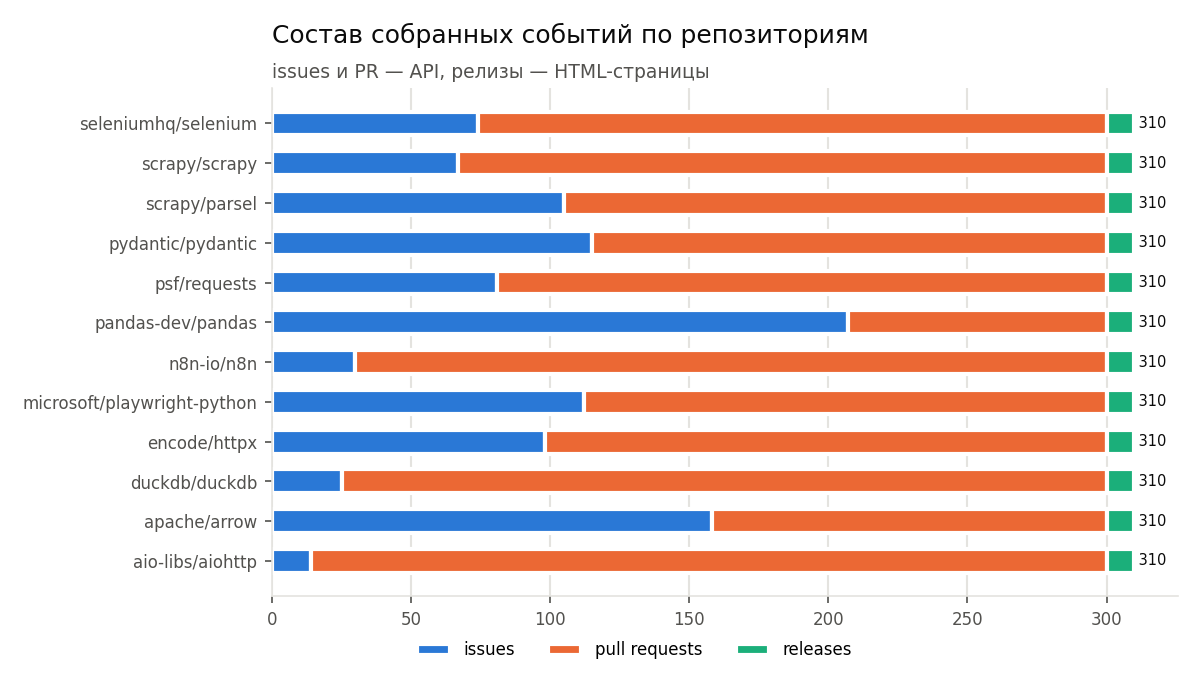

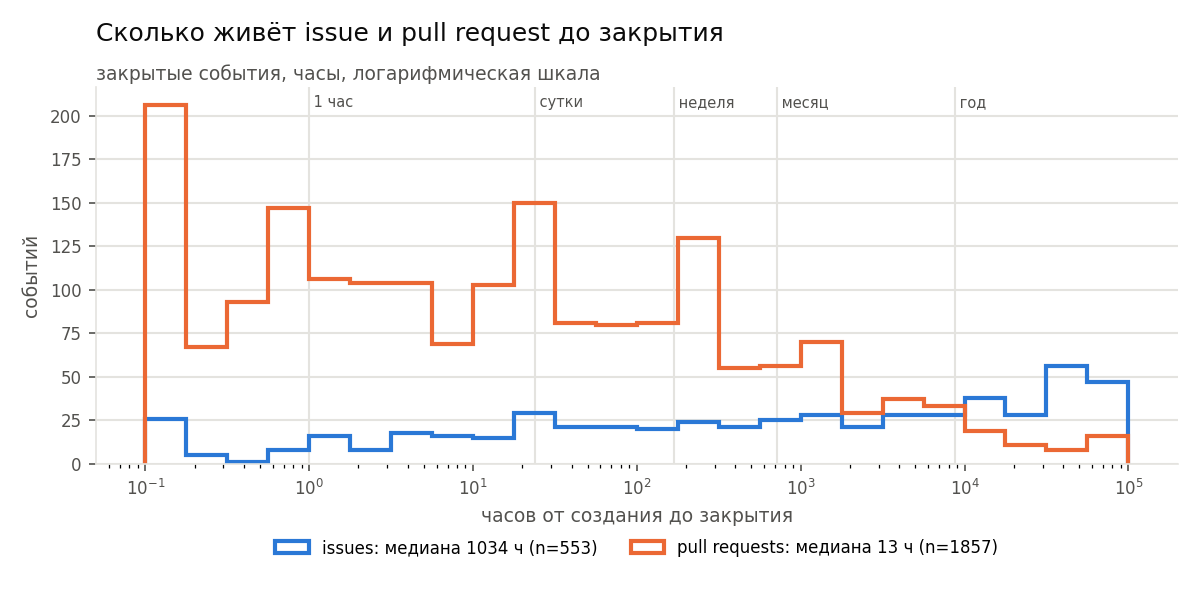

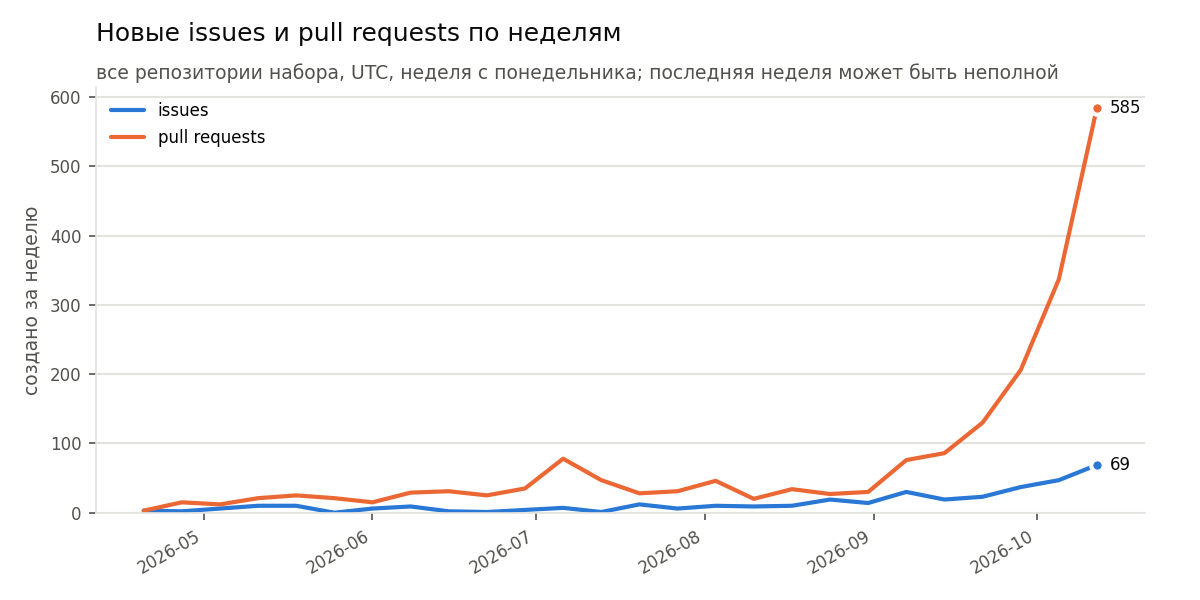

In [20]:
for png in sorted((config.MART_DIR / "charts").glob("*.png")):
    display(Image(filename=str(png)))

## 9. Задание повышенной сложности: DuckDB по Parquet против SQLite

In [21]:
if config.WAREHOUSE_DB.exists():
    display(duckdb_bench.run())

,запрос,строк результата,"DuckDB по Parquet, мс","SQLite, мс",результаты совпали
0,события по репозиторию и типу,36,0.65,1.04,True
1,"среднее время закрытия, ч",12,1.70,0.81,True
2,новые события по неделям,443,1.34,1.10,True


## 10. Выводы

1. **Сырой слой** — неизменяемые JSON Lines с происхождением каждой записи. HTML-значения хранятся «как на странице», поэтому clean пересобирается без сети, и результат совпадает побайтно по содержимому (раздел 5).
2. **Формат хранения** выбран по замеру (раздел 2). CSV теряет типы: дату, целые с пропусками, списки, а на партии из одних цифр — и ведущие нули. Parquet возвращает типы без потерь и меньше по размеру, поэтому clean и mart хранятся в Parquet, а CSV используется только для обмена.
3. **Очистка и контракт** ловят разные классы дефектов. Шаги 1–2 превращают почти-дубли в обычные дубли, шаг 4 отсекает записи без обязательных полей, правила шага 6 — логические противоречия, контракт — формат значений. Ни одна запись не удаляется молча: всё попадает в rejects с причиной.
4. **UPSERT с условием по `row_hash`** даёт идемпотентность. Повторный прогон ничего не меняет, а при изменении двух записей обновляются ровно они, и SCD2 сохраняет обе версии (раздел 6).
5. **«Светофор»** переводит качество в решение: красный статус любой метрики останавливает загрузку в mart (раздел 7).